In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from feature_engine.selection import MRMR

#Plot MRMR value over top N pics. can also show genomic distribution of selected SNPs

In [2]:
class_tab = pd.read_csv('train_barcode.csv')

class_tab = class_tab.set_index('Sample') 

In [3]:
class_tab.shape

(209, 2999)

In [4]:
data_target = class_tab.loc[:,'Species']
                            
data_predictors = class_tab.iloc[:,class_tab.columns!='Species']

In [5]:
predictors = data_predictors.columns.tolist()

In [6]:
barcode_lengths = [5, 10, 15, 20, 25, 30, 40, 50, 75, 100]

for length in barcode_lengths: 
    sel = MRMR(variables = predictors, method="MIQ", max_features=length, discrete_features = True, regression=False, random_state=42)
    sel.fit(data_predictors, data_target)

    sel_feats = [v for v in sel.variables_ if v not in sel.features_to_drop_]

    with open(f"MRMR_subsets/top_{length}_MRMR", 'w+') as f:

        for items in sel_feats:
            f.write('%s\n' %items)

    f.close()

/jupyter/home/.local/lib/python3.9/site-packages/feature_engine/selection/mrmr.py:465: RuntimeWarning: divide by zero encountered in divide
  mrmr = relevance / redundance
/jupyter/home/.local/lib/python3.9/site-packages/feature_engine/selection/mrmr.py:465: RuntimeWarning: divide by zero encountered in divide
  mrmr = relevance / redundance
/jupyter/home/.local/lib/python3.9/site-packages/feature_engine/selection/mrmr.py:465: RuntimeWarning: divide by zero encountered in divide
  mrmr = relevance / redundance
/jupyter/home/.local/lib/python3.9/site-packages/feature_engine/selection/mrmr.py:465: RuntimeWarning: divide by zero encountered in divide
  mrmr = relevance / redundance
/jupyter/home/.local/lib/python3.9/site-packages/feature_engine/selection/mrmr.py:465: RuntimeWarning: divide by zero encountered in divide
  mrmr = relevance / redundance
/jupyter/home/.local/lib/python3.9/site-packages/feature_engine/selection/mrmr.py:465: RuntimeWarning: divide by zero encountered in divide


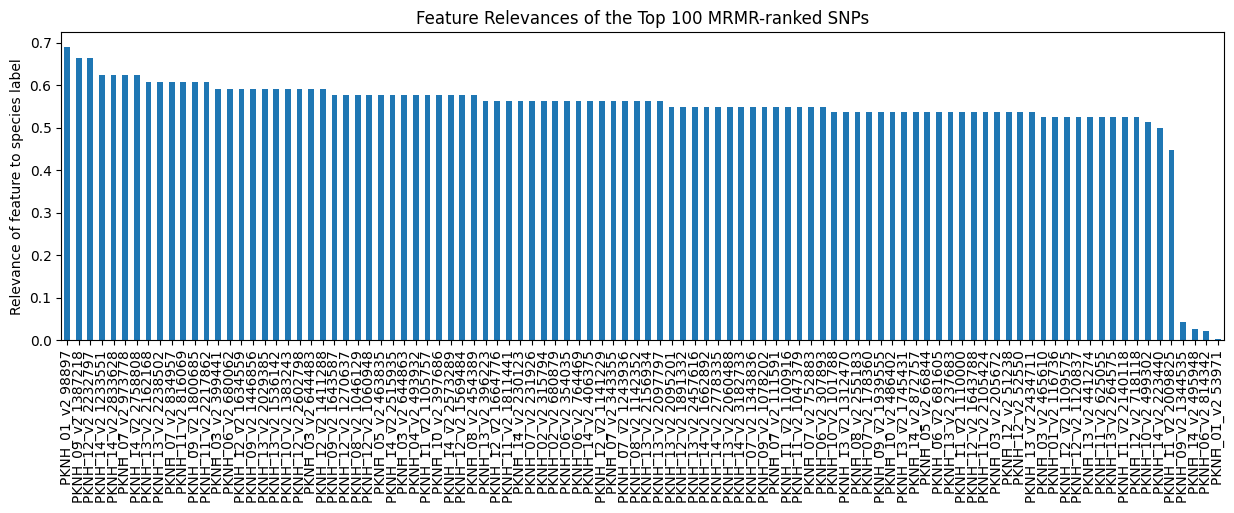

In [8]:
rel = pd.Series(sel.relevance_, index=sel.variables_)
selected_rel = rel.drop(sel.features_to_drop_).sort_values(ascending=False)

selected_rel.plot.bar(figsize=(15, 4),color='red')
plt.title("Feature Relevances of the Top 100 MRMR-ranked SNPs")
plt.ylabel("Relevance of feature to location label")
plt.savefig('MRMR_rels.png',bbox_inches='tight', dpi=300)